<a href="https://colab.research.google.com/github/sumitsartale4952/Study-_materials/blob/main/Nvida_Stock_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# Step1: import required lib

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
# Step 2: Load the datasets

df = pd.read_csv('/content/nvda_stock.csv')

In [3]:
# Step 3: Data Expoloration

df.head()

,Date,Open,High,Low,Close,Volume
0,2010-01-04,0.424242,0.426763,0.415074,0.423784,800204000
1,2010-01-05,0.422179,0.434556,0.422179,0.429972,728648000
2,2010-01-06,0.429743,0.433639,0.425617,0.432722,649168000
3,2010-01-07,0.430430,0.432264,0.421033,0.424242,547792000
4,2010-01-08,0.420804,0.428139,0.418283,0.425159,478168000


In [4]:
df.shape

(4108, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4108 entries, 0 to 4107
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4108 non-null   object 
 1   Open    4108 non-null   float64
 2   High    4108 non-null   float64
 3   Low     4108 non-null   float64
 4   Close   4108 non-null   float64
 5   Volume  4108 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 192.7+ KB


In [6]:
# Step 4: Data Preprocessing

# 1: handled the date columns

df['Date'] = pd.to_datetime(df['Date'])
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

In [7]:
# drop the Date

df.drop("Date",axis = True , inplace = True )

In [8]:
df.head()

,Open,High,Low,Close,Volume,year,month,day
0,0.424242,0.426763,0.415074,0.423784,800204000,2010,1,4
1,0.422179,0.434556,0.422179,0.429972,728648000,2010,1,5
2,0.429743,0.433639,0.425617,0.432722,649168000,2010,1,6
3,0.430430,0.432264,0.421033,0.424242,547792000,2010,1,7
4,0.420804,0.428139,0.418283,0.425159,478168000,2010,1,8


In [9]:
# Step 5: Divide the data into x and y varibale

X = df.drop('Close', axis = True)
y = df['Close']

In [10]:
# Step 6: Split the datasets into train and test parts '

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# Step 7: Feature Engineering

# create the instance of model
scaler = StandardScaler()

# fit and transfrom train data to the scaling
X_train = scaler.fit_transform(X_train)

# fit and transfrom test data to the scaling
X_test = scaler.transform(X_test)

In [36]:
# Step 8: Model Building

model  = Sequential()

model.add(Dense(128, activation='relu',kernel_initializer='he_normal', input_shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu',kernel_initializer='he_normal'))
model.add(Dense(32, activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1, activation='linear'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
# Step 9: compile the model

# learning rate Scheduler

# 1 option : Exponential Decay

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.001,
    decay_steps=100,
    decay_rate=0.9
)

# compile the model

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,      # learning Rate
    clipnorm = 1.0)           # gradient Clipping

model.compile(
    optimizer = optimizer,
    loss = 'mean_squared_error',
    metrics = ['r2_score']
)



In [38]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,393 (44.50 KB)

 Trainable params: 11,393 (44.50 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Step 10 : Train the Model
history = model.fit(X_train,y_train,
                    epochs=20,
                    batch_size=32,
                    validation_data = (X_test,y_test),
                    validation_split=0.2,
                    verbose = True
                    )

Epoch 1/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 1359.5120 - r2_score: 0.4395 - val_loss: 14.9340 - val_r2_score: 0.9940
Epoch 2/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.5486 - r2_score: 0.9973 - val_loss: 4.5679 - val_r2_score: 0.9982
Epoch 3/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.3418 - r2_score: 0.9982 - val_loss: 3.3783 - val_r2_score: 0.9986
Epoch 4/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.3295 - r2_score: 0.9986 - val_loss: 2.5831 - val_r2_score: 0.9990
Epoch 5/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.7312 - r2_score: 0.9989 - val_loss: 2.4008 - val_r2_score: 0.9990
Epoch 6/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4070 - r2_score: 0.9990 - val_loss: 2.1053 - val_r2_score: 0.9992
Epoch 7/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.1113 - r2_score: 0.9991 - val_loss: 1.7669 - val_r2_score: 0.9993
Epoch 8/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9904 - r2_score: 0.9992 - val_loss: 1

In [40]:
# Model Evalute

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R-squared Score:", r2)



26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Mean Squared Error: 0.7884904785789955
Mean Absolute Error: 0.5167847842685064
R-squared Score: 0.9996820438384942


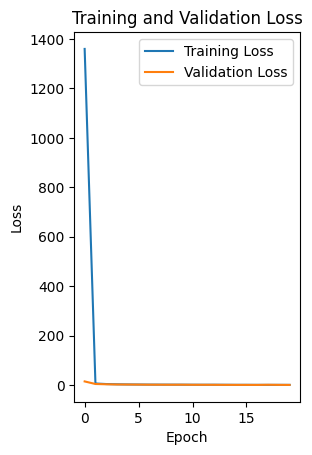

In [41]:

# Step 13 : Plot Training History
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

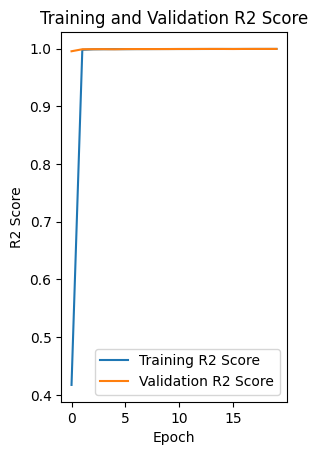

In [30]:
# Step 14: plot the r2 score history

plt.subplot(1, 2, 2)
plt.plot(history.history['r2_score'], label='Training R2 Score')
plt.plot(history.history['val_r2_score'], label='Validation R2 Score')
plt.title('Training and Validation R2 Score')
plt.xlabel('Epoch')
plt.ylabel('R2 Score')
plt.legend()
plt.show()